[I 2026-01-16 21:02:04,719] A new study created in memory with name: no-name-1c29dd4a-c9fa-45fe-bad3-24ddcb2836eb
[I 2026-01-16 21:02:13,272] Trial 0 finished with value: 8.278173124393554 and parameters: {'hemi_q_low': 0.060000000000000005, 'cell_q_low': 0.03, 'lignin_q_low': 0.02, 'rare_ratio': 0.8, 'n_jitter': 250, 'n_residual': 200, 'beta_lo': 0.25, 'beta_hi': 0.7000000000000001, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.7999999999999999, 'colsample_bytree': 0.8999999999999999}. Best is trial 0 with value: 8.278173124393554.
[I 2026-01-16 21:02:22,147] Trial 1 finished with value: 8.907361659480413 and parameters: {'hemi_q_low': 0.04, 'cell_q_low': 0.01, 'lignin_q_low': 0.04, 'rare_ratio': 0.8, 'n_jitter': 100, 'n_residual': 100, 'beta_lo': 0.15000000000000002, 'beta_hi': 0.6000000000000001, 'max_depth': 6, 'learning_rate': 0.08, 'subsample': 0.8999999999999999, 'colsample_bytree': 0.7999999999999999}. Best is trial 0 with value: 8.278173124393554.
[I 2026-01-16 21:02:2


===== OPTUNA BEST =====
Best score: 7.660034433243652
Best params: {'hemi_q_low': 0.06999999999999999, 'cell_q_low': 0.02, 'lignin_q_low': 0.04, 'rare_ratio': 0.7, 'n_jitter': 100, 'n_residual': 200, 'beta_lo': 0.25, 'beta_hi': 0.4, 'max_depth': 6, 'learning_rate': 0.03, 'subsample': 0.7, 'colsample_bytree': 0.8999999999999999}
Best attrs: {'mean_rmse': 13.415419371722955, 'mean_r2': 0.6186019588093076, 'mean_tail_mae': 7.69164329442586, 'hemi_tail_rmse': 17.92163374844915, 'cell_tail_rmse': 5.6896527607786735, 'lignin_tail_rmse': 3.8487164380202437, 'r2_hemi': 0.5004644767993844, 'r2_cell': 0.547714500392755, 'r2_lignin': 0.807626899235783}

===== BEST EXPORT =====
Mean over repeats: MAE=7.0411, RMSE=13.4154, R2=0.6186
Mean R2 per target over repeats: Hemi=0.5005, Cell=0.5477, Lignin=0.8076
Mean tail RMSE: Hemi=17.9216, Cell=5.6897, Lignin=3.8487
Last run: MAE=7.8292, RMSE=14.7635, R2=0.4942
R2 per target (last run): {'Hemicellulose': 0.3648263788551943, 'Cellulose': 0.31170453477395

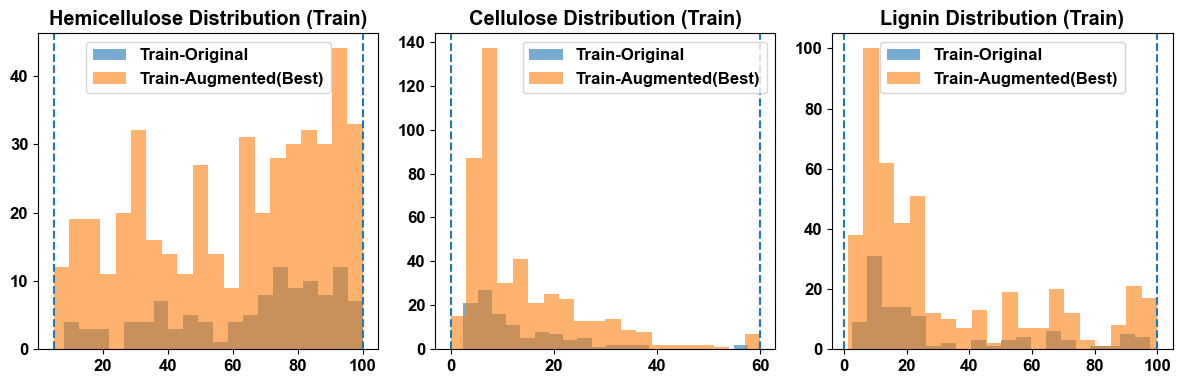

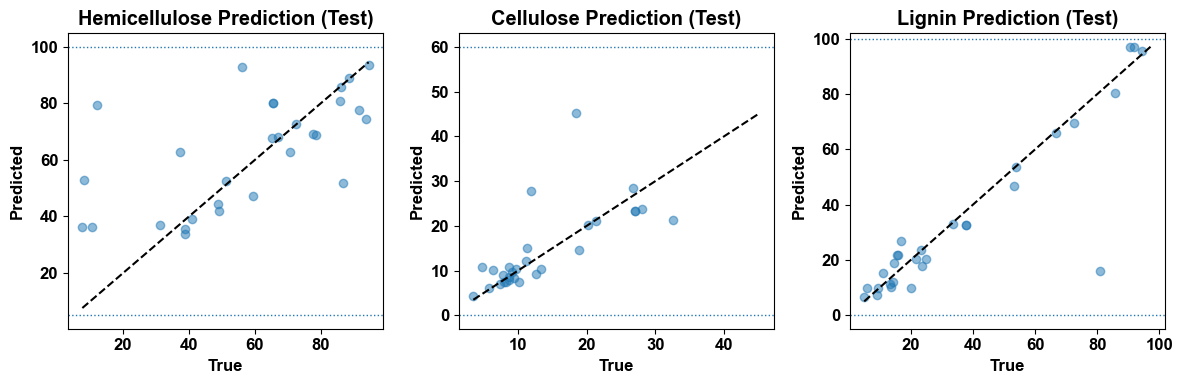

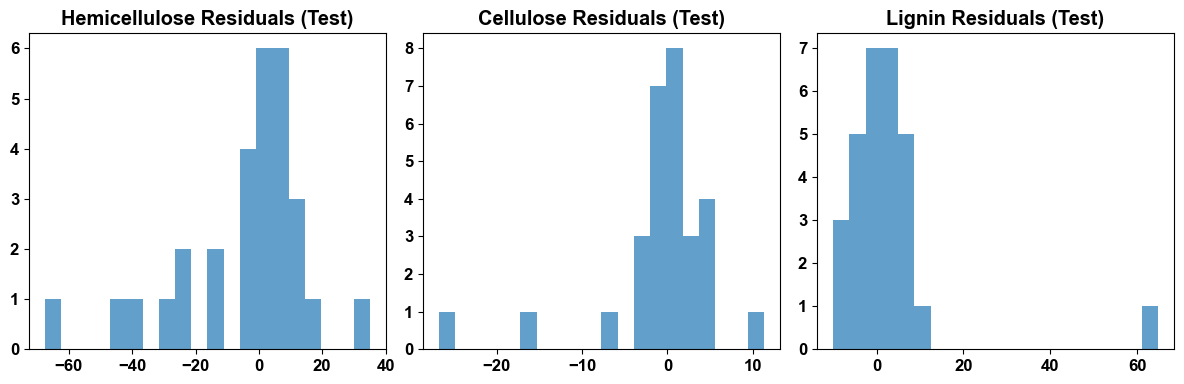

In [11]:
# -*- coding: utf-8 -*-
"""
多目标回归：自动调参（综合 Hemicellulose + Cellulose + Lignin 尾部）
Pipeline: SMOTER + Jitter + ResidualAug + XGB(MultiOutput)

改动要点（已合并）：
1) 打印/记录每个目标单独的 R2：r2_hemi / r2_cell / r2_lignin
2) per_target_metrics 里新增 R2 列
3) tail_error 增加 n_tail==0 的保护，避免报错

依赖：
pip install optuna xgboost openpyxl scikit-learn matplotlib
"""

import warnings
warnings.filterwarnings("ignore")

import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from typing import Optional, Dict, Any

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor


# ====================== 基础配置 ======================
DATA_PATH = "数据集.xlsx"
OUTPUT_PATH = "数据集_augmented_final.xlsx"

TARGET_COLS = ["Hemicellulose", "Cellulose", "Lignin"]

TARGET_RANGES = {
    "Hemicellulose": (5.0, 100.0),
    "Cellulose":     (0.0, 60.0),
    "Lignin":        (0.0, 100.0),
}

NOISE_SETTINGS = {
    "Concentration": 0.5,
    "TEMP":          1.0,
    "time":          2.0,
}

FEATURE_BOUNDS = {
    "Concentration": (0.0, None),
    "time":          (0.0, None),
    # "TEMP": (0.0, 250.0),
}

# 回弹 eps（每个目标可不同）
CLIP_EPS_PER_TARGET = {
    "Hemicellulose": 1e-3,
    "Cellulose":     1e-3,
    "Lignin":        1e-3,
}

# 评估尾部用：固定（建议 0.10/0.90 保证 n_tail 稳定）
EVAL_Q_PER_TARGET = {
    "Hemicellulose": (0.10, 0.90),
    "Cellulose":     (0.10, 0.90),
    "Lignin":        (0.10, 0.90),
}

K_NEIGHBORS = 10

# 固定 test 的划分种子（关键）
SPLIT_SEED = 42

# Optuna trial 次数
N_TRIALS = 60

# 每个 trial 重复次数（建议 3~5）
N_REPEATS = 3

# 评分权重（整体优先，其次兼顾尾部；加入 R2）
W_OVERALL = 0.65
W_HEMI_TAIL = 0.12
W_CELL_TAIL = 0.12
W_LIGNIN_TAIL = 0.06
W_R2 = 0.05  # 以 (1-R2) 形式进入最小化目标
# =====================================================


# ====================== 标注配置（新增） ======================
META_COLS = ["row_id", "origin", "parent_id_1", "parent_id_2", "aug_step", "source_id"]

def ensure_base_tags(df: pd.DataFrame) -> pd.DataFrame:
    """若没有标注列，则为原始数据补齐标注列（幂等，可重复调用）"""
    df = df.copy().reset_index(drop=True)

    if "row_id" not in df.columns or df["row_id"].isna().any():
        df["row_id"] = np.arange(len(df), dtype=int)
    else:
        df["row_id"] = df["row_id"].astype(int)

    if "origin" not in df.columns:
        df["origin"] = "Original"
    if "parent_id_1" not in df.columns:
        df["parent_id_1"] = df["row_id"].astype(int)
    if "parent_id_2" not in df.columns:
        df["parent_id_2"] = -1
    if "aug_step" not in df.columns:
        df["aug_step"] = "None"
    if "source_id" not in df.columns:
        df["source_id"] = df["row_id"].astype(int)

    return df

def next_row_id(df: pd.DataFrame) -> int:
    if "row_id" not in df.columns or df["row_id"].isna().all():
        return 0
    return int(df["row_id"].max()) + 1

def apply_aug_tags(
    df_new: pd.DataFrame,
    start_id: int,
    parent1: np.ndarray,
    parent2: Optional[np.ndarray],
    aug_step: str
) -> pd.DataFrame:
    """给新增增强样本批量打标，确保 row_id 唯一，且可追溯父样本"""
    df_new = df_new.copy().reset_index(drop=True)
    n = len(df_new)
    df_new["row_id"] = np.arange(start_id, start_id + n, dtype=int)
    df_new["origin"] = "Augmented"
    df_new["parent_id_1"] = parent1.astype(int)
    df_new["parent_id_2"] = (-1 if parent2 is None else parent2.astype(int))
    df_new["aug_step"] = aug_step

    # source_id 用于分组（避免同源泄漏）
    if parent2 is None:
        df_new["source_id"] = df_new["parent_id_1"].astype(int)
    else:
        a = np.minimum(df_new["parent_id_1"].to_numpy(), df_new["parent_id_2"].to_numpy()).astype(int)
        b = np.maximum(df_new["parent_id_1"].to_numpy(), df_new["parent_id_2"].to_numpy()).astype(int)
        df_new["source_id"] = pd.Series(a.astype(str)) + "_" + pd.Series(b.astype(str))

    return df_new
# =============================================================


# ------------------ 工具函数 ------------------
def clip_with_rebound_df(
    df: pd.DataFrame,
    target_cols,
    ranges,
    eps_per_target=None,
    eps=1e-3
) -> pd.DataFrame:
    """回弹裁剪：越界回到边界内 eps，减少边界尖峰"""
    df = df.copy()
    for c in target_cols:
        lo, hi = ranges[c]
        x = df[c].astype(float)
        eps_c = float(eps_per_target.get(c, eps)) if isinstance(eps_per_target, dict) else float(eps)
        x = np.where(x < lo, lo + eps_c, x)
        x = np.where(x > hi, hi - eps_c, x)
        df[c] = x
    return df


def split_feature_cols(df: pd.DataFrame, target_cols):
    # 关键：把 META_COLS 和 target_cols 都排除（避免字符串列进入模型）
    feature_cols = [c for c in df.columns if c not in target_cols and c not in META_COLS]
    num_cols = [c for c in feature_cols if np.issubdtype(df[c].dtype, np.number)]
    cat_cols = [c for c in feature_cols if c not in num_cols]
    return feature_cols, num_cols, cat_cols


def make_X(df: pd.DataFrame, num_cols, cat_cols, ref_columns=None):
    X_num = df[num_cols].copy() if len(num_cols) else pd.DataFrame(index=df.index)
    X_cat = pd.get_dummies(df[cat_cols], dummy_na=True) if len(cat_cols) else pd.DataFrame(index=df.index)
    X = pd.concat([X_num, X_cat], axis=1)
    if ref_columns is not None:
        X = X.reindex(columns=ref_columns, fill_value=0)
    return X


def jitter(
    df: pd.DataFrame,
    noise_settings,
    feature_bounds=None,
    n_samples=200,
    seed=42
) -> pd.DataFrame:
    """只对指定工艺列加噪声；并对新增样本打标（JITTER）"""
    df = df.copy()
    rng_local = np.random.default_rng(seed)
    aug_rows = []
    parent1 = []

    for _ in range(n_samples):
        i = int(rng_local.integers(0, len(df)))
        row = df.iloc[i].copy()

        pid = int(df.iloc[i]["row_id"]) if "row_id" in df.columns else int(i)
        parent1.append(pid)

        for c, sigma in noise_settings.items():
            if c in df.columns and np.issubdtype(df[c].dtype, np.number):
                row[c] = float(row[c]) + float(rng_local.normal(0, sigma))
                if feature_bounds and c in feature_bounds:
                    lo, hi = feature_bounds[c]
                    if lo is not None and row[c] < lo:
                        row[c] = lo
                    if hi is not None and row[c] > hi:
                        row[c] = hi

        aug_rows.append(row)

    df_new = pd.DataFrame(aug_rows)
    start_id = next_row_id(df)
    df_new = apply_aug_tags(df_new, start_id, np.array(parent1), None, "JITTER")

    out = pd.concat([df, df_new], ignore_index=True)
    out = clip_with_rebound_df(out, TARGET_COLS, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)
    return out


def smoter(
    df: pd.DataFrame,
    target_cols,
    num_feature_cols,
    cat_feature_cols,
    rare_ratio=0.8,
    q_per_target=None,
    rng=None
) -> pd.DataFrame:
    """
    SMOTER：尾部插值增强
    rare 判定：任一目标落在各自分位数外（OR）
    并对新增样本打标（SMOTER；双亲）
    """
    df = df.copy()
    rng = rng or np.random.default_rng(0)

    rare_mask = np.zeros(len(df), dtype=bool)
    mid_mask = np.ones(len(df), dtype=bool)

    for c in target_cols:
        if isinstance(q_per_target, dict) and c in q_per_target:
            lq, hq = q_per_target[c]
        else:
            lq, hq = 0.05, 0.95

        lo, hi = df[c].quantile([lq, hq]).values
        rare_mask |= (df[c] <= lo) | (df[c] >= hi)
        mid_mask &= (df[c] > lo) & (df[c] < hi)

    n_mid, n_rare = int(mid_mask.sum()), int(rare_mask.sum())
    target_rare = max(n_rare, int(rare_ratio * n_mid))
    need = max(0, target_rare - n_rare)

    if need == 0 or len(df) < 2:
        return df

    X_nn = make_X(df, num_feature_cols, cat_feature_cols)
    Xv = X_nn.values
    nn = NearestNeighbors(n_neighbors=min(K_NEIGHBORS, len(df))).fit(Xv)

    aug_rows = []
    parent_i = []
    parent_j = []

    rare_indices = np.where(rare_mask)[0]

    for _ in range(need):
        i = int(rng.choice(rare_indices))
        _, neighs = nn.kneighbors([Xv[i]], n_neighbors=min(K_NEIGHBORS, len(df)))
        cand = neighs[0][1:] if len(neighs[0]) > 1 else neighs[0]
        j = int(rng.choice(cand))
        alpha = float(rng.uniform(0.2, 0.8))

        row = {}
        for col in num_feature_cols:
            row[col] = (1 - alpha) * df.iloc[i][col] + alpha * df.iloc[j][col]
        for col in cat_feature_cols:
            row[col] = df.iloc[i][col]
        for col in target_cols:
            row[col] = (1 - alpha) * df.iloc[i][col] + alpha * df.iloc[j][col]

        aug_rows.append(row)

        pid_i = int(df.iloc[i]["row_id"]) if "row_id" in df.columns else int(i)
        pid_j = int(df.iloc[j]["row_id"]) if "row_id" in df.columns else int(j)
        parent_i.append(pid_i)
        parent_j.append(pid_j)

    df_new = pd.DataFrame(aug_rows)
    start_id = next_row_id(df)
    df_new = apply_aug_tags(df_new, start_id, np.array(parent_i), np.array(parent_j), "SMOTER")

    out = pd.concat([df, df_new], ignore_index=True)
    out = clip_with_rebound_df(out, target_cols, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)
    return out


def residual_augmentation(
    df: pd.DataFrame,
    target_cols,
    num_cols,
    cat_cols,
    base_estimator,
    n_samples=200,
    beta_range=(0.1, 0.6),
    max_attempts=5000,
    rng=None
) -> pd.DataFrame:
    """
    残差增强：自适应 beta 上界（保证 y_new 不越界）
    并对新增样本打标（RESIDUAL；单亲）
    """
    df = df.copy()
    rng = rng or np.random.default_rng(0)

    model = MultiOutputRegressor(base_estimator)

    X_df = make_X(df, num_cols, cat_cols)
    X = X_df.values
    y = df[target_cols].values.astype(float)

    kf = KFold(n_splits=5, shuffle=True, random_state=123)
    preds = np.zeros_like(y, dtype=float)

    for tr_idx, te_idx in kf.split(X):
        model.fit(X[tr_idx], y[tr_idx])
        preds[te_idx] = model.predict(X[te_idx])

    residuals = y - preds

    lows = np.array([TARGET_RANGES[c][0] for c in target_cols], dtype=float)
    highs = np.array([TARGET_RANGES[c][1] for c in target_cols], dtype=float)

    beta_lo_global, beta_hi_global = beta_range

    aug_rows = []
    parent1 = []
    attempts = 0

    while len(aug_rows) < n_samples and attempts < max_attempts:
        attempts += 1
        i = int(rng.integers(0, len(df)))
        row = df.iloc[i].copy()

        y0 = row[target_cols].values.astype(float)
        r = residuals[i].astype(float)

        beta_max_list = []
        for k in range(len(target_cols)):
            if r[k] > 0:
                beta_max_k = (highs[k] - y0[k]) / r[k]
            elif r[k] < 0:
                beta_max_k = (lows[k] - y0[k]) / r[k]
            else:
                beta_max_k = np.inf
            beta_max_list.append(beta_max_k)

        beta_max = float(np.min(beta_max_list))
        if (not np.isfinite(beta_max)) or (beta_max <= 0):
            continue

        beta_hi = min(beta_hi_global, beta_max)
        if beta_hi <= 0:
            continue

        beta_lo = min(beta_lo_global, beta_hi)
        beta = float(rng.uniform(beta_lo, beta_hi))

        y_new = y0 + beta * r
        if np.all(y_new >= lows) and np.all(y_new <= highs):
            row[target_cols] = y_new
            pid = int(df.iloc[i]["row_id"]) if "row_id" in df.columns else int(i)
            parent1.append(pid)
            aug_rows.append(row)

    if len(aug_rows) < n_samples:
        print(f"[WARN] residual_augmentation: 只生成了 {len(aug_rows)}/{n_samples} 条（attempts={attempts}）")

    df_new = pd.DataFrame(aug_rows)
    if len(df_new) > 0:
        start_id = next_row_id(df)
        df_new = apply_aug_tags(df_new, start_id, np.array(parent1), None, "RESIDUAL")
        out = pd.concat([df, df_new], ignore_index=True)
    else:
        out = df.copy()

    out = clip_with_rebound_df(out, target_cols, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)
    return out


def tail_error(y_true, y_pred, target_cols, q_per_target=None):
    """按给定分位数定义 tail，并计算每个目标 tail MAE/RMSE；tail为空则返回 NaN"""
    res = {}
    for i, c in enumerate(target_cols):
        lq, hq = q_per_target.get(c, (0.10, 0.90)) if isinstance(q_per_target, dict) else (0.10, 0.90)
        lo, hi = np.quantile(y_true[:, i], [lq, hq])
        mask = (y_true[:, i] <= lo) | (y_true[:, i] >= hi)
        n_tail = int(mask.sum())

        if n_tail == 0:
            res[c] = {"MAE": float("nan"), "RMSE": float("nan"), "n_tail": 0}
            continue

        mae = mean_absolute_error(y_true[mask, i], y_pred[mask, i])
        rmse = np.sqrt(mean_squared_error(y_true[mask, i], y_pred[mask, i]))
        res[c] = {"MAE": float(mae), "RMSE": float(rmse), "n_tail": n_tail}
    return res


def per_target_metrics(y_true, y_pred, target_cols):
    rows = []
    for i, c in enumerate(target_cols):
        rows.append({
            "target": c,
            "MAE": float(mean_absolute_error(y_true[:, i], y_pred[:, i])),
            "RMSE": float(np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))),
            "R2": float(r2_score(y_true[:, i], y_pred[:, i])),
        })
    return pd.DataFrame(rows)


# ------------------ 一次完整训练评估 ------------------
def run_once(df_train_raw, df_test, num_cols, cat_cols, cfg, seed_aug):
    rng_local = np.random.default_rng(seed_aug)

    # Step 1: SMOTER
    df_train_1 = smoter(
        df_train_raw, TARGET_COLS, num_cols, cat_cols,
        rare_ratio=cfg["rare_ratio"],
        q_per_target=cfg["smoter_q_per_target"],
        rng=rng_local
    )

    # Step 2: Jitter
    df_train_2 = jitter(
        df_train_1, NOISE_SETTINGS, feature_bounds=FEATURE_BOUNDS,
        n_samples=cfg["n_jitter"], seed=seed_aug
    )

    # Step 3: ResidualAug
    base_est = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=cfg["base_n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],
        subsample=cfg["subsample"],
        colsample_bytree=cfg["colsample_bytree"],
        random_state=seed_aug
    )

    df_train_aug = residual_augmentation(
        df_train_2, TARGET_COLS, num_cols, cat_cols,
        base_estimator=base_est,
        n_samples=cfg["n_residual"],
        beta_range=cfg["beta_range"],
        max_attempts=cfg["max_attempts"],
        rng=rng_local
    )

    # Train final model
    X_train_df = make_X(df_train_aug, num_cols, cat_cols)
    ref_cols = X_train_df.columns.tolist()
    X_test_df = make_X(df_test, num_cols, cat_cols, ref_columns=ref_cols)

    y_train = df_train_aug[TARGET_COLS].values.astype(float)
    y_test = df_test[TARGET_COLS].values.astype(float)

    final_est = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=cfg["final_n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],
        subsample=cfg["subsample"],
        colsample_bytree=cfg["colsample_bytree"],
        random_state=seed_aug
    )
    final_model = MultiOutputRegressor(final_est)
    final_model.fit(X_train_df.values, y_train)

    preds = final_model.predict(X_test_df.values)

    preds_df = pd.DataFrame(preds, columns=TARGET_COLS)
    preds_df = clip_with_rebound_df(preds_df, TARGET_COLS, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)
    preds_clip = preds_df.values

    mae = float(mean_absolute_error(y_test, preds_clip))
    rmse = float(np.sqrt(mean_squared_error(y_test, preds_clip)))
    r2 = float(r2_score(y_test, preds_clip, multioutput="uniform_average"))

    # 每个目标单独 R2（关键）
    r2_each = {c: float(r2_score(y_test[:, i], preds_clip[:, i])) for i, c in enumerate(TARGET_COLS)}

    tail = tail_error(y_test, preds_clip, TARGET_COLS, q_per_target=EVAL_Q_PER_TARGET)
    tail_mae_mean = float(np.nanmean([tail[c]["MAE"] for c in TARGET_COLS]))

    return mae, rmse, r2, r2_each, tail_mae_mean, tail, df_train_aug


# ------------------ 固定 split + repeats 的稳健评估 ------------------
def evaluate_config(df_all, cfg, split_seed=SPLIT_SEED, n_repeats=N_REPEATS):
    df_all = ensure_base_tags(df_all)
    df_all = clip_with_rebound_df(df_all, TARGET_COLS, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)

    df_train_raw, df_test = train_test_split(
        df_all, test_size=0.2, random_state=split_seed, shuffle=True
    )
    _, num_cols, cat_cols = split_feature_cols(df_train_raw, TARGET_COLS)

    maes, rmses, r2s, tail_maes = [], [], [], []
    hemi_tail_rmse_list, cell_tail_rmse_list, lignin_tail_rmse_list = [], [], []

    # 每个目标的 R2 统计
    r2_hemi_list, r2_cell_list, r2_lignin_list = [], [], []

    last_aug = None

    for k in range(n_repeats):
        seed_aug = split_seed * 1000 + 17 * (k + 1) + cfg["seed_offset"]
        mae, rmse, r2, r2_each, tmae, tail, df_aug = run_once(df_train_raw, df_test, num_cols, cat_cols, cfg, seed_aug)

        maes.append(mae)
        rmses.append(rmse)
        r2s.append(r2)
        tail_maes.append(tmae)

        hemi_tail_rmse_list.append(float(tail["Hemicellulose"]["RMSE"]))
        cell_tail_rmse_list.append(float(tail["Cellulose"]["RMSE"]))
        lignin_tail_rmse_list.append(float(tail["Lignin"]["RMSE"]))

        r2_hemi_list.append(float(r2_each["Hemicellulose"]))
        r2_cell_list.append(float(r2_each["Cellulose"]))
        r2_lignin_list.append(float(r2_each["Lignin"]))

        last_aug = df_aug

    mean_mae = float(np.mean(maes))
    mean_rmse = float(np.mean(rmses))
    mean_r2 = float(np.mean(r2s))
    mean_tail_mae = float(np.mean(tail_maes))

    mean_hemi_tail_rmse = float(np.mean(hemi_tail_rmse_list))
    mean_cell_tail_rmse = float(np.mean(cell_tail_rmse_list))
    mean_lignin_tail_rmse = float(np.mean(lignin_tail_rmse_list))

    mean_r2_hemi = float(np.mean(r2_hemi_list))
    mean_r2_cell = float(np.mean(r2_cell_list))
    mean_r2_lignin = float(np.mean(r2_lignin_list))

    return (mean_mae, mean_rmse, mean_r2, mean_tail_mae,
            mean_hemi_tail_rmse, mean_cell_tail_rmse, mean_lignin_tail_rmse,
            mean_r2_hemi, mean_r2_cell, mean_r2_lignin,
            df_train_raw, df_test, last_aug)


# ------------------ Optuna 配置构造（加入 Lignin 阈值搜索） ------------------
def build_cfg_from_trial(trial: optuna.Trial) -> Dict[str, Any]:
    hemi_q_low   = trial.suggest_float("hemi_q_low",   0.01, 0.08, step=0.01)
    cell_q_low   = trial.suggest_float("cell_q_low",   0.01, 0.08, step=0.01)
    lignin_q_low = trial.suggest_float("lignin_q_low", 0.01, 0.08, step=0.01)

    cfg = {
        "smoter_q_per_target": {
            "Hemicellulose": (hemi_q_low, 1.0 - hemi_q_low),
            "Cellulose":     (cell_q_low, 1.0 - cell_q_low),
            "Lignin":        (lignin_q_low, 1.0 - lignin_q_low),
        },

        "rare_ratio": trial.suggest_float("rare_ratio", 0.6, 0.9, step=0.1),

        "n_jitter": trial.suggest_int("n_jitter", 100, 300, step=50),
        "n_residual": trial.suggest_int("n_residual", 100, 300, step=50),

        "beta_range": (
            trial.suggest_float("beta_lo", 0.05, 0.25, step=0.05),
            trial.suggest_float("beta_hi", 0.40, 0.80, step=0.10),
        ),
        "max_attempts": 5000,

        "max_depth": trial.suggest_int("max_depth", 4, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.08, step=0.01),
        "subsample": trial.suggest_float("subsample", 0.7, 0.9, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 0.9, step=0.1),

        "base_n_estimators": 200,
        "final_n_estimators": 300,

        "seed_offset": trial.number * 13 + 7,
    }

    if cfg["beta_range"][0] > cfg["beta_range"][1]:
        cfg["beta_range"] = (cfg["beta_range"][1], cfg["beta_range"][0])

    return cfg


# ------------------ 目标函数（加入 R2；加入 Lignin 尾部；记录 per-target R2） ------------------
def objective(trial: optuna.Trial, df_all: pd.DataFrame):
    cfg = build_cfg_from_trial(trial)

    (mean_mae, mean_rmse, mean_r2, mean_tail_mae,
     mean_hemi_tail_rmse, mean_cell_tail_rmse, mean_lignin_tail_rmse,
     mean_r2_hemi, mean_r2_cell, mean_r2_lignin,
     *_ ) = evaluate_config(df_all, cfg, split_seed=SPLIT_SEED, n_repeats=N_REPEATS)

    # 最小化：MAE + 各尾部RMSE + (1-R2)
    score = (W_OVERALL * mean_mae
             + W_HEMI_TAIL * mean_hemi_tail_rmse
             + W_CELL_TAIL * mean_cell_tail_rmse
             + W_LIGNIN_TAIL * mean_lignin_tail_rmse
             + W_R2 * (1.0 - mean_r2))

    trial.set_user_attr("mean_rmse", float(mean_rmse))
    trial.set_user_attr("mean_r2", float(mean_r2))
    trial.set_user_attr("mean_tail_mae", float(mean_tail_mae))
    trial.set_user_attr("hemi_tail_rmse", float(mean_hemi_tail_rmse))
    trial.set_user_attr("cell_tail_rmse", float(mean_cell_tail_rmse))
    trial.set_user_attr("lignin_tail_rmse", float(mean_lignin_tail_rmse))

    # 关键：每个目标单独 R2
    trial.set_user_attr("r2_hemi", float(mean_r2_hemi))
    trial.set_user_attr("r2_cell", float(mean_r2_cell))
    trial.set_user_attr("r2_lignin", float(mean_r2_lignin))

    return float(score)


# ------------------ 用 best_cfg 导出结果 ------------------
def export_with_best(df_all: pd.DataFrame, best_cfg: dict):
    (mean_mae, mean_rmse, mean_r2, mean_tail_mae,
     mean_hemi_tail_rmse, mean_cell_tail_rmse, mean_lignin_tail_rmse,
     mean_r2_hemi, mean_r2_cell, mean_r2_lignin,
     df_train_raw, df_test, _df_train_aug_last) = evaluate_config(
        df_all, best_cfg, split_seed=SPLIT_SEED, n_repeats=N_REPEATS
    )

    _, num_cols, cat_cols = split_feature_cols(df_train_raw, TARGET_COLS)
    seed_aug = SPLIT_SEED * 1000 + 17 * N_REPEATS + best_cfg["seed_offset"]

    mae, rmse, r2, r2_each, tmae, tail, df_train_aug = run_once(df_train_raw, df_test, num_cols, cat_cols, best_cfg, seed_aug)

    X_train_df = make_X(df_train_aug, num_cols, cat_cols)
    ref_cols = X_train_df.columns.tolist()
    X_test_df = make_X(df_test, num_cols, cat_cols, ref_columns=ref_cols)

    y_train = df_train_aug[TARGET_COLS].values.astype(float)
    y_test = df_test[TARGET_COLS].values.astype(float)

    final_est = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=best_cfg["final_n_estimators"],
        max_depth=best_cfg["max_depth"],
        learning_rate=best_cfg["learning_rate"],
        subsample=best_cfg["subsample"],
        colsample_bytree=best_cfg["colsample_bytree"],
        random_state=seed_aug
    )
    final_model = MultiOutputRegressor(final_est)
    final_model.fit(X_train_df.values, y_train)

    preds = final_model.predict(X_test_df.values)
    preds_df = pd.DataFrame(preds, columns=TARGET_COLS)
    preds_df = clip_with_rebound_df(preds_df, TARGET_COLS, TARGET_RANGES, eps_per_target=CLIP_EPS_PER_TARGET)
    preds_clip = preds_df.values

    per_target = per_target_metrics(y_test, preds_clip, TARGET_COLS)

    report_overall = pd.DataFrame([{
        "SPLIT_SEED": SPLIT_SEED,
        "N_REPEATS": N_REPEATS,
        "W_OVERALL": W_OVERALL,
        "W_HEMI_TAIL": W_HEMI_TAIL,
        "W_CELL_TAIL": W_CELL_TAIL,
        "W_LIGNIN_TAIL": W_LIGNIN_TAIL,
        "W_R2": W_R2,
        "MAE_last": float(mae),
        "RMSE_last": float(rmse),
        "R2_last": float(r2),
        "R2_last_each": str(r2_each),
        "Tail_last": str(tail),
        "Mean_MAE_over_repeats": float(mean_mae),
        "Mean_RMSE_over_repeats": float(mean_rmse),
        "Mean_R2_over_repeats": float(mean_r2),
        "Mean_R2_each_over_repeats": str({
            "Hemicellulose": mean_r2_hemi,
            "Cellulose": mean_r2_cell,
            "Lignin": mean_r2_lignin
        }),
        "Mean_tailMAE_over_repeats": float(mean_tail_mae),
        "Mean_hemi_tailRMSE": float(mean_hemi_tail_rmse),
        "Mean_cell_tailRMSE": float(mean_cell_tail_rmse),
        "Mean_lignin_tailRMSE": float(mean_lignin_tail_rmse),
        "BEST_CFG": str(best_cfg),
    }])

    with pd.ExcelWriter(OUTPUT_PATH, engine="openpyxl") as writer:
        df_train_raw.to_excel(writer, index=False, sheet_name="train_original")
        df_train_aug.to_excel(writer, index=False, sheet_name="train_augmented_best")
        df_test.to_excel(writer, index=False, sheet_name="test_original")
        report_overall.to_excel(writer, index=False, sheet_name="report_overall")
        per_target.to_excel(writer, index=False, sheet_name="per_target_metrics")

    print("\n===== BEST EXPORT =====")
    print(f"Mean over repeats: MAE={mean_mae:.4f}, RMSE={mean_rmse:.4f}, R2={mean_r2:.4f}")
    print(f"Mean R2 per target over repeats: Hemi={mean_r2_hemi:.4f}, Cell={mean_r2_cell:.4f}, Lignin={mean_r2_lignin:.4f}")
    print(f"Mean tail RMSE: Hemi={mean_hemi_tail_rmse:.4f}, Cell={mean_cell_tail_rmse:.4f}, Lignin={mean_lignin_tail_rmse:.4f}")
    print(f"Last run: MAE={mae:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}")
    print("R2 per target (last run):", r2_each)
    print("Tail(last):", tail)
    print(per_target)
    print(f"Saved to: {OUTPUT_PATH}")

    mpl.rcParams.update({
        "font.family": "Arial",
        "font.size": 12,
        "font.weight": "bold",
        "axes.labelweight": "bold",
        "axes.titleweight": "bold",
        "pdf.fonttype": 42,
        "ps.fonttype": 42
    })

    # (A) 目标分布
    plt.figure(figsize=(12, 4))
    for i, c in enumerate(TARGET_COLS):
        plt.subplot(1, 3, i + 1)
        plt.hist(df_train_raw[c], bins=20, alpha=0.6, label="Train-Original")
        plt.hist(df_train_aug[c], bins=20, alpha=0.6, label="Train-Augmented(Best)")
        lo, hi = TARGET_RANGES[c]
        plt.axvline(lo, linestyle="--")
        plt.axvline(hi, linestyle="--")
        plt.title(f"{c} Distribution (Train)")
        plt.legend()
    plt.tight_layout()
    plt.savefig("distribution_train_original_vs_augmented_best.pdf")
    plt.show()

    # (B) 预测 vs 真实
    plt.figure(figsize=(12, 4))
    for i, c in enumerate(TARGET_COLS):
        plt.subplot(1, 3, i + 1)
        plt.scatter(y_test[:, i], preds_clip[:, i], alpha=0.5)
        diag_lo = min(y_test[:, i].min(), preds_clip[:, i].min())
        diag_hi = max(y_test[:, i].max(), preds_clip[:, i].max())
        plt.plot([diag_lo, diag_hi], [diag_lo, diag_hi], "k--")
        lo_clip, hi_clip = TARGET_RANGES[c]
        plt.axhline(lo_clip, linestyle=":", linewidth=1)
        plt.axhline(hi_clip, linestyle=":", linewidth=1)
        plt.xlabel("True")
        plt.ylabel("Predicted")
        plt.title(f"{c} Prediction (Test)")
    plt.tight_layout()
    plt.savefig("prediction_scatter_test_best.pdf")
    plt.show()

    # (C) 残差直方图
    plt.figure(figsize=(12, 4))
    for i, c in enumerate(TARGET_COLS):
        plt.subplot(1, 3, i + 1)
        plt.hist(y_test[:, i] - preds_clip[:, i], bins=20, alpha=0.7)
        plt.title(f"{c} Residuals (Test)")
    plt.tight_layout()
    plt.savefig("residual_histogram_test_best.pdf")
    plt.show()


def main():
    df_all = pd.read_excel(DATA_PATH)

    for c in TARGET_COLS:
        if c not in df_all.columns:
            raise ValueError(f"缺少目标列: {c}")

    df_all = ensure_base_tags(df_all)

    sampler = optuna.samplers.TPESampler(seed=123)
    study = optuna.create_study(direction="minimize", sampler=sampler)

    def _obj(trial):
        return objective(trial, df_all)

    study.optimize(_obj, n_trials=N_TRIALS)

    print("\n===== OPTUNA BEST =====")
    print("Best score:", study.best_value)
    print("Best params:", study.best_params)
    print("Best attrs:", study.best_trial.user_attrs)

    best_cfg = build_cfg_from_trial(study.best_trial)
    export_with_best(df_all, best_cfg)


if __name__ == "__main__":
    main()


In [4]:
import os
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from math import sqrt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import ElasticNet


# ============== 0) 你需要改的地方 ==============
SEED = 42
CV_SPLITS = 5

# 单目标列名：改成你的目标列（比如 "Y" 或 "Lignin" 或 "Selectivity"）
TARGET_COL = "Y"

# 只用这些列作为特征（按你截图的特征列）
FEATURES = [
    "C","M","H","O","Ph","NO3","CH3","OH","COOH","N","CO",
    "Concentration","TEMP","BP","MP","VCOS","time"
]

# 元数据列（永远不进特征）
META_COLS = ["row_id", "origin", "parent_id_1", "parent_id_2", "aug_step", "source_id", "group_id"]

# === 输入文件路径 ===
# 方案A：增强训练集 + 原始测试集（推荐）
TRAIN_AUG_PATH = "train_aug.xlsx"
TEST_ORIG_PATH = "test_original.xlsx"

# 方案B：只有一个增强后的总表（如果你没有 TEST_ORIG_PATH，把它设为 None，并给 ALL_DATA_PATH）
ALL_DATA_PATH = None  # 例如 "数据集_augmented_final.xlsx"

# 输出
OUT_DIR = "trained_models"
os.makedirs(OUT_DIR, exist_ok=True)
# =============================================


In [5]:
# ============== 1) 可选库检测：XGB / LGBM ==============
xgb_available = False
try:
    from xgboost import XGBRegressor
    xgb_available = True
except Exception:
    pass

lgbm_available = False
try:
    from lightgbm import LGBMRegressor
    lgbm_available = True
except Exception:
    pass


In [6]:
# ============== 2) group_id：用 row_id + parent_id_1/2 连通分量构造 ==============
def add_group_id(df: pd.DataFrame,
                 row_col="row_id",
                 p1_col="parent_id_1",
                 p2_col="parent_id_2",
                 out_col="group_id") -> pd.DataFrame:
    df = df.copy()

    if row_col not in df.columns:
        df[row_col] = np.arange(len(df), dtype=int)

    row_id = pd.to_numeric(df[row_col], errors="coerce").astype("Int64")

    p1 = pd.to_numeric(df[p1_col], errors="coerce").astype("Int64") if p1_col in df.columns else pd.Series([pd.NA]*len(df), dtype="Int64")
    p2 = pd.to_numeric(df[p2_col], errors="coerce").astype("Int64") if p2_col in df.columns else pd.Series([pd.NA]*len(df), dtype="Int64")

    # 把 <0 当缺失
    p1 = p1.mask(p1 < 0)
    p2 = p2.mask(p2 < 0)

    nodes = pd.concat([row_id, p1, p2], ignore_index=True).dropna().astype(int).unique()
    nodes = np.array(nodes, dtype=int)
    if len(nodes) == 0:
        df[out_col] = -1
        return df

    idx = {nid: i for i, nid in enumerate(nodes)}
    parent = np.arange(len(nodes), dtype=int)
    rank = np.zeros(len(nodes), dtype=int)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb:
            return
        if rank[ra] < rank[rb]:
            parent[ra] = rb
        elif rank[ra] > rank[rb]:
            parent[rb] = ra
        else:
            parent[rb] = ra
            rank[ra] += 1

    for r, a, b in zip(row_id.to_numpy(), p1.to_numpy(), p2.to_numpy()):
        if pd.isna(r):
            continue
        r = int(r)
        ir = idx[r]
        if not pd.isna(a):
            union(ir, idx[int(a)])
        if not pd.isna(b):
            union(ir, idx[int(b)])
        if (not pd.isna(a)) and (not pd.isna(b)):
            union(idx[int(a)], idx[int(b)])

    comp_min = {}
    for nid in nodes:
        root = find(idx[int(nid)])
        comp_min[root] = min(comp_min.get(root, nid), nid)

    group_ids = []
    for r in row_id.to_numpy():
        if pd.isna(r):
            group_ids.append(-1)
        else:
            root = find(idx[int(r)])
            group_ids.append(comp_min[root])

    df[out_col] = np.array(group_ids, dtype=int)
    return df


In [7]:
# ============== 3) 数据读取与构造 Train/Test ==============
def clean_xy(df: pd.DataFrame):
    miss = [c for c in FEATURES + [TARGET_COL] if c not in df.columns]
    if miss:
        raise ValueError(f"缺少列: {miss}")

    X = df[FEATURES].copy()
    y = df[TARGET_COL].astype(float).copy()

    # 丢掉缺失
    mask = ~(X.isna().any(axis=1) | y.isna())
    X = X.loc[mask].reset_index(drop=True)
    y = y.loc[mask].reset_index(drop=True)
    return X, y, mask


def load_train_test():
    # 方案A：两个文件
    if TEST_ORIG_PATH is not None and os.path.exists(TEST_ORIG_PATH):
        if not os.path.exists(TRAIN_AUG_PATH):
            raise ValueError(f"找不到 TRAIN_AUG_PATH: {TRAIN_AUG_PATH}")

        df_train = pd.read_excel(TRAIN_AUG_PATH)
        df_test = pd.read_excel(TEST_ORIG_PATH)

        df_train = add_group_id(df_train)  # 训练集必须有 group_id 用于 CV
        if "row_id" in df_test.columns:
            df_test = add_group_id(df_test)

        return df_train, df_test

    # 方案B：单文件自动切 test（从 origin==Original 抽 group）
    if ALL_DATA_PATH is None:
        raise ValueError("你没有提供 TEST_ORIG_PATH，也没有提供 ALL_DATA_PATH。请二选一。")
    if not os.path.exists(ALL_DATA_PATH):
        raise ValueError(f"找不到 ALL_DATA_PATH: {ALL_DATA_PATH}")

    df_all = pd.read_excel(ALL_DATA_PATH)
    df_all = add_group_id(df_all)

    if "origin" not in df_all.columns:
        raise ValueError("单文件模式要求有 origin 列（Original/Augmented），否则无法安全抽 test。")

    df_orig = df_all[df_all["origin"].astype(str).str.lower().str.contains("original")].copy()
    if len(df_orig) < 10:
        raise ValueError("Original 行太少，无法可靠划分 test。建议使用方案A：提供原始 test 文件。")

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    Xo, yo, _ = clean_xy(df_orig)
    groups_o = df_orig.loc[Xo.index, "group_id"].to_numpy()

    tr_idx, te_idx = next(gss.split(Xo, yo, groups=groups_o))
    test_groups = set(groups_o[te_idx].tolist())

    # test：只取这些 group 的 Original 行
    df_test = df_orig.iloc[te_idx].copy()

    # train：全体数据里剔除这些 test group（包括其 Augmented）
    df_train = df_all[~df_all["group_id"].isin(test_groups)].copy()

    return df_train, df_test


In [8]:
# ============== 4) 评估函数 ==============
def eval_reg(y_true, y_pred, prefix=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"[{prefix}] MAE={mae:.4f} | RMSE={rmse:.4f} | R2={r2:.4f}")
    return {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)}


def pipe(estimator, need_scale=False):
    steps = []
    if need_scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)


def grid_size(param_grid: dict) -> int:
    n = 1
    for _, v in param_grid.items():
        n *= len(v)
    return n

In [13]:
# -*- coding: utf-8 -*-
"""
单目标回归：GroupKFold + GridSearchCV（尽量避免增强数据的同源泄露）
数据源：一个 Excel 工作簿，包含 sheet:
- train_augmented_best
- test_original

依赖：
pip install scikit-learn pandas numpy openpyxl joblib
可选：
pip install xgboost lightgbm
"""

import os
import numpy as np
import pandas as pd
import joblib

from math import sqrt
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import ElasticNet


# ===================== 0) 你需要改的地方 =====================
SEED = 42
CV_SPLITS = 5

# 你的数据文件（工作簿）
BOOK_PATH = "数据集_augmented_final.xlsx"   # ← 改成你的实际路径/文件名

# 单目标列名：你的表里没有 "Y"，只能选这三个之一
TARGET_COL = "Hemicellulose"  # ← 改成 "Hemicellulose" / "Cellulose" / "Lignin"

# 只用这些列做特征（严格不包含 meta）
FEATURES = [
    "C","M","H","O","Ph","NO3","CH3","OH","COOH","N","CO",
    "Concentration","TEMP","BP","MP","VCOS","time"
]

# 元数据列（不会入模，仅用于分组/追溯）
META_COLS = ["row_id", "origin", "parent_id_1", "parent_id_2", "aug_step", "source_id", "group_id"]

# 输出目录
OUT_DIR = "trained_models"
os.makedirs(OUT_DIR, exist_ok=True)
# ============================================================


# ===================== 1) 可选库检测：XGB / LGBM =====================
xgb_available = False
try:
    from xgboost import XGBRegressor
    xgb_available = True
except Exception:
    pass

lgbm_available = False
try:
    from lightgbm import LGBMRegressor
    lgbm_available = True
except Exception:
    pass


# ===================== 2) group_id：row_id + parent_id_1/2 连通分量 =====================
def add_group_id(df: pd.DataFrame,
                 row_col="row_id",
                 p1_col="parent_id_1",
                 p2_col="parent_id_2",
                 out_col="group_id") -> pd.DataFrame:
    """
    把“原始样本 + 其所有派生样本（SMOTER/Jitter/Residual）”锁在同一组。
    做法：把 row_id / parent_id_1 / parent_id_2 当图的节点，用并查集求连通分量。
    """
    df = df.copy().reset_index(drop=True)

    if row_col not in df.columns:
        df[row_col] = np.arange(len(df), dtype=int)

    row_id = pd.to_numeric(df[row_col], errors="coerce").astype("Int64")

    p1 = pd.to_numeric(df[p1_col], errors="coerce").astype("Int64") if p1_col in df.columns else pd.Series([pd.NA]*len(df), dtype="Int64")
    p2 = pd.to_numeric(df[p2_col], errors="coerce").astype("Int64") if p2_col in df.columns else pd.Series([pd.NA]*len(df), dtype="Int64")

    # <0 当缺失
    p1 = p1.mask(p1 < 0)
    p2 = p2.mask(p2 < 0)

    nodes = pd.concat([row_id, p1, p2], ignore_index=True).dropna().astype(int).unique()
    nodes = np.array(nodes, dtype=int)

    if len(nodes) == 0:
        df[out_col] = -1
        return df

    idx = {nid: i for i, nid in enumerate(nodes)}
    parent = np.arange(len(nodes), dtype=int)
    rank = np.zeros(len(nodes), dtype=int)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb:
            return
        if rank[ra] < rank[rb]:
            parent[ra] = rb
        elif rank[ra] > rank[rb]:
            parent[rb] = ra
        else:
            parent[rb] = ra
            rank[ra] += 1

    for r, a, b in zip(row_id.to_numpy(), p1.to_numpy(), p2.to_numpy()):
        if pd.isna(r):
            continue
        r = int(r)
        ir = idx[r]
        if not pd.isna(a):
            union(ir, idx[int(a)])
        if not pd.isna(b):
            union(ir, idx[int(b)])
        if (not pd.isna(a)) and (not pd.isna(b)):
            union(idx[int(a)], idx[int(b)])

    # 用每个连通分量里最小的 node id 作为 group_id（稳定、可读）
    comp_min = {}
    for nid in nodes:
        root = find(idx[int(nid)])
        comp_min[root] = min(comp_min.get(root, nid), nid)

    group_ids = []
    for r in row_id.to_numpy():
        if pd.isna(r):
            group_ids.append(-1)
        else:
            root = find(idx[int(r)])
            group_ids.append(comp_min[root])

    df[out_col] = np.array(group_ids, dtype=int)
    return df


# ===================== 3) 读数据（固定用你这个工作簿的两个 sheet） =====================
def load_train_test_from_book(book_path: str):
    if not os.path.exists(book_path):
        raise FileNotFoundError(f"找不到文件：{book_path}\n当前目录：{os.getcwd()}")

    # 你这个文件就是这两个 sheet
    df_train = pd.read_excel(book_path, sheet_name="train_augmented_best")
    df_test  = pd.read_excel(book_path, sheet_name="test_original")

    # 训练集必须能分组
    df_train = add_group_id(df_train)
    df_test  = add_group_id(df_test)
    return df_train, df_test


def clean_xy(df: pd.DataFrame):
    miss = [c for c in FEATURES + [TARGET_COL] if c not in df.columns]
    if miss:
        raise ValueError(f"缺少列: {miss}")

    X = df[FEATURES].copy()
    # 强制数值化（避免 Excel 读成 object）
    X = X.apply(pd.to_numeric, errors="coerce")

    y = pd.to_numeric(df[TARGET_COL], errors="coerce")

    mask = ~(X.isna().any(axis=1) | y.isna())
    X = X.loc[mask].reset_index(drop=True)
    y = y.loc[mask].reset_index(drop=True)
    return X, y, mask


# ===================== 4) 评估/管道/网格规模 =====================
def eval_reg(y_true, y_pred, prefix=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"[{prefix}] MAE={mae:.4f} | RMSE={rmse:.4f} | R2={r2:.4f}")
    return {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)}

def pipe(estimator, need_scale=False):
    steps = []
    if need_scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

def grid_size(param_grid: dict) -> int:
    n = 1
    for _, v in param_grid.items():
        n *= len(v)
    return n


# ===================== 5) 模型空间（含 LGBM；<=600 fits） =====================
def build_model_spaces():
    spaces = {
        "DT": {
            "pipeline": pipe(DecisionTreeRegressor(random_state=SEED), need_scale=False),
            "param_grid": {
                "model__max_depth": [None, 3, 5, 7, 10],
                "model__min_samples_split": [2, 5, 10],
                "model__min_samples_leaf": [1, 2, 4],
            },
        },
        "RF": {
            "pipeline": pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1), need_scale=False),
            "param_grid": {
                "model__n_estimators": [200, 500],
                "model__max_depth": [None, 10, 20],
                "model__min_samples_split": [2, 5],
                "model__min_samples_leaf": [1, 2],
                "model__max_features": ["sqrt", 1.0],
            },
        },
        "GBDT": {
            "pipeline": pipe(GradientBoostingRegressor(random_state=SEED), need_scale=False),
            "param_grid": {
                "model__n_estimators": [300, 600, 1000],
                "model__learning_rate": [0.01, 0.05, 0.1],
                "model__max_depth": [2, 3, 4],
                "model__subsample": [1.0, 0.8, 0.7],
            },
        },
        "SVM": {
            "pipeline": pipe(SVR(), need_scale=True),
            "param_grid": {
                "model__kernel": ["rbf"],
                "model__C": [1, 10, 100],
                "model__gamma": ["scale", "auto", 0.1, 0.01],
                "model__epsilon": [0.1, 0.2, 0.3],
            },
        },
        "ANN": {
            "pipeline": pipe(MLPRegressor(random_state=SEED, max_iter=2000, early_stopping=True), need_scale=True),
            "param_grid": {
                "model__hidden_layer_sizes": [(64, 64), (128, 64), (128, 128)],
                "model__alpha": [1e-4, 1e-3, 1e-2],
                "model__learning_rate_init": [1e-3, 3e-3, 1e-2],
                "model__activation": ["relu"],
            },
        },
        "ET": {
            "pipeline": pipe(ExtraTreesRegressor(random_state=SEED, n_jobs=-1), need_scale=False),
            "param_grid": {
                "model__n_estimators": [500, 1000],
                "model__max_depth": [None, 12, 20],
                "model__min_samples_split": [2, 5],
                "model__min_samples_leaf": [1, 2],
                "model__max_features": ["sqrt", 0.8, 1.0],
                "model__bootstrap": [False],
            },
        },
        "EN": {
            "pipeline": pipe(ElasticNet(max_iter=20000, random_state=SEED), need_scale=True),
            "param_grid": {
                "model__alpha": list(np.logspace(-3, 1, 5)),
                "model__l1_ratio": [0.05, 0.25, 0.5, 0.75, 0.95],
                "model__fit_intercept": [True, False],
            },
        },
    }

    # XGB（可选）
    if xgb_available:
        spaces["XGB"] = {
            "pipeline": pipe(
                XGBRegressor(
                    random_state=SEED,
                    objective="reg:squarederror",
                    tree_method="hist",
                    n_jobs=-1
                ),
                need_scale=False
            ),
            "param_grid": {
                "model__n_estimators": [500, 1000],
                "model__max_depth": [4, 6, 8],
                "model__learning_rate": [0.01, 0.05, 0.1],
                "model__subsample": [0.7, 1.0],
                "model__colsample_bytree": [0.7, 1.0],
                "model__reg_alpha": [0, 1e-2],
                "model__reg_lambda": [1, 5],
            },
        }
    else:
        print("[INFO] xgboost 未安装，跳过 XGB。")

    # LGBM（新增；组合 96；CV=5 -> 96*5+1=481 <= 600）
    if lgbm_available:
        spaces["LGBM"] = {
            "pipeline": pipe(
                LGBMRegressor(
                    random_state=SEED,
                    n_jobs=-1,
                    objective="regression",
                    subsample_freq=1,
                ),
                need_scale=False
            ),
            "param_grid": {
                "model__n_estimators": [1200],
                "model__num_leaves": [31, 63, 127],     # 3
                "model__max_depth": [-1, 10],           # 2
                "model__learning_rate": [0.03, 0.07],   # 2
                "model__subsample": [0.8, 1.0],         # 2
                "model__colsample_bytree": [0.8, 1.0],  # 2
                "model__min_child_samples": [10, 20],   # 2
            },
        }
    else:
        print("[INFO] lightgbm 未安装，跳过 LGBM。")

    return spaces


# ===================== 6) 主流程 =====================
def main():
    df_train, df_test = load_train_test_from_book(BOOK_PATH)

    X_train, y_train, mask_train = clean_xy(df_train)
    X_test,  y_test,  mask_test  = clean_xy(df_test)

    # groups 对齐（用 group_id，最稳）
    df_train_clean = df_train.loc[mask_train].reset_index(drop=True)
    if "group_id" not in df_train_clean.columns:
        df_train_clean = add_group_id(df_train_clean)
    groups = df_train_clean["group_id"].to_numpy()

    n_groups = len(np.unique(groups))
    n_splits = min(CV_SPLITS, n_groups)
    if n_splits < 2:
        raise ValueError(f"可用 group 数量不足：n_groups={n_groups}（<2）。请检查 row_id/parent_id 是否有效。")

    cv = GroupKFold(n_splits=n_splits)
    scoring = "neg_mean_absolute_error"

    print("Workbook:", BOOK_PATH)
    print("Target:", TARGET_COL)
    print("Train:", X_train.shape, "| Test:", X_test.shape)
    print("Unique groups:", n_groups, "| GroupKFold splits:", n_splits)
    print("Scoring:", scoring)

    model_spaces = build_model_spaces()

    # LGBM fits 检查
    if "LGBM" in model_spaces:
        combos = grid_size(model_spaces["LGBM"]["param_grid"])
        total_fits = combos * n_splits + 1
        print(f"[CHECK] LGBM combos={combos}, cv_splits={n_splits}, total_fits≈{total_fits} (<=600)")

    fitted_models = {}
    results = {}
    best_by_cv = {"name": None, "score": -np.inf, "estimator": None}

    for name, space in model_spaces.items():
        print(f"\n===== {name} | GridSearchCV(cv=GroupKFold {n_splits}) | scoring={scoring} =====")

        gs = GridSearchCV(
            estimator=space["pipeline"],
            param_grid=space["param_grid"],
            scoring=scoring,
            cv=cv,
            n_jobs=-1,
            verbose=1,
            refit=True
        )

        # 关键：groups=groups（防同源泄露）
        gs.fit(X_train.values, y_train.values, groups=groups)

        best_model = gs.best_estimator_
        best_cv_score = gs.best_score_

        print("Best params:", gs.best_params_)
        print("Best CV MAE:", -best_cv_score)

        # test 评估（用于对比；严格科研流程应“CV选模型后再看一次test”）
        test_pred = best_model.predict(X_test.values)
        t = eval_reg(y_test.values, test_pred, prefix=f"{name}-TEST")

        save_path = os.path.join(OUT_DIR, f"{name}_best.pkl")
        joblib.dump(best_model, save_path)
        print("Saved ->", save_path)

        fitted_models[name] = best_model
        results[name] = {"best_params": gs.best_params_, "CV_negMAE": float(best_cv_score), "TEST": t}

        if best_cv_score > best_by_cv["score"]:
            best_by_cv = {"name": name, "score": best_cv_score, "estimator": best_model}

    print("\n===== FINAL (by CV, recommended) =====")
    print("Final model:", best_by_cv["name"])
    print("Final CV MAE:", -best_by_cv["score"])

    final_model = best_by_cv["estimator"]
    final_pred = final_model.predict(X_test.values)
    final_metrics = eval_reg(y_test.values, final_pred, prefix="FINAL-TEST")

    final_path = os.path.join(OUT_DIR, f"FINAL_{best_by_cv['name']}.pkl")
    joblib.dump(final_model, final_path)
    print("Final saved ->", final_path)

    # 汇总报告
    rows = []
    for k, v in results.items():
        rows.append({
            "model": k,
            "CV_MAE": -v["CV_negMAE"],
            "TEST_MAE": v["TEST"]["MAE"],
            "TEST_RMSE": v["TEST"]["RMSE"],
            "TEST_R2": v["TEST"]["R2"],
            "best_params": str(v["best_params"])
        })
    df_report = pd.DataFrame(rows).sort_values("CV_MAE")
    report_path = os.path.join(OUT_DIR, "report_models.xlsx")
    df_report.to_excel(report_path, index=False)
    print("Report ->", report_path)


if __name__ == "__main__":
    main()

Workbook: 数据集_augmented_final.xlsx
Target: Hemicellulose
Train: (452, 17) | Test: (29, 17)
Unique groups: 82 | GroupKFold splits: 5
Scoring: neg_mean_absolute_error
[CHECK] LGBM combos=96, cv_splits=5, total_fits≈481 (<=600)

===== DT | GridSearchCV(cv=GroupKFold 5) | scoring=neg_mean_absolute_error =====
Fitting 5 folds for each of 45 candidates, totalling 225 fits
Best params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}
Best CV MAE: 22.405175319698262
[DT-TEST] MAE=12.5634 | RMSE=20.3349 | R2=0.4088
Saved -> trained_models\DT_best.pkl

===== RF | GridSearchCV(cv=GroupKFold 5) | scoring=neg_mean_absolute_error =====
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best params: {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV MAE: 18.14313337453524
[RF-TEST] MAE=14.8829 | RMSE=21.1402 | R2=0.3611
Saved -> trained_models\RF_best

c:\Users\79971\miniconda3\envs\test_env_1\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.863e+03, tolerance: 3.581e+01
  model = cd_fast.enet_coordinate_descent(


Best params: {'model__alpha': 0.001, 'model__fit_intercept': True, 'model__l1_ratio': 0.95}
Best CV MAE: 14.800705993904192
[EN-TEST] MAE=14.4736 | RMSE=17.4252 | R2=0.5659
Saved -> trained_models\EN_best.pkl

===== XGB | GridSearchCV(cv=GroupKFold 5) | scoring=neg_mean_absolute_error =====
Fitting 5 folds for each of 288 candidates, totalling 1440 fits
Best params: {'model__colsample_bytree': 0.7, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 1000, 'model__reg_alpha': 0, 'model__reg_lambda': 1, 'model__subsample': 1.0}
Best CV MAE: 17.162297266022556
[XGB-TEST] MAE=14.8158 | RMSE=22.6110 | R2=0.2691
Saved -> trained_models\XGB_best.pkl

===== LGBM | GridSearchCV(cv=GroupKFold 5) | scoring=neg_mean_absolute_error =====
Fitting 5 folds for each of 96 candidates, totalling 480 fits


KeyboardInterrupt: 